# Review 2: Time-Series Analysis (TMDB movies)
Run the cells in order. Change the settings in the first cell if your choices differ.

## Step 1: Setup and data preparation

In [1]:
import os, ast, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (12, 4)

PATH = "data/processed/tmdb_clean.csv"
MIN_V = 20        # movies with fewer votes are not used for rating averages
DROP_LAST = 12    # newest months have few votes, so they are shown but not modelled
TEST = 24         # months held out for testing
H_FC = 12         # months to forecast
TOP = 6           # genres tracked
os.makedirs("data/ts", exist_ok=True)

df = pd.read_csv(PATH, parse_dates=["release_date"])
df["genres"] = df["genres"].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
df["ym"] = df["release_date"].dt.to_period("M").dt.to_timestamp()
df["yr"] = df["release_date"].dt.year
r = df[df["vote_count"] >= MIN_V]

# monthly series (one row per month)
idx = pd.date_range(df["ym"].min(), df["ym"].max(), freq="MS")
mon = pd.DataFrame({"rating": r.groupby("ym")["vote_average"].mean(),
                    "pop": df.groupby("ym")["popularity"].mean(),
                    "n_all": df.groupby("ym").size(),
                    "n_rated": r.groupby("ym").size()}).reindex(idx)
print("months:", len(mon), "| months with no rated movie:", mon["rating"].isna().sum())
mon[["rating", "pop"]] = mon[["rating", "pop"]].interpolate()
mon["used"] = np.arange(len(mon)) < len(mon) - DROP_LAST

s = mon.loc[mon["used"], "rating"].asfreq("MS")      # main series: monthly average rating
sp = mon.loc[mon["used"], "pop"].asfreq("MS")        # monthly average popularity
print("series used:", s.index.min().date(), "to", s.index.max().date(), "| points:", len(s))
print("rated movies per month: min", int(mon["n_rated"].min()), "| median", int(mon["n_rated"].median()))

# yearly view: rating, popularity and share of the top genres
ge = df.explode("genres")
top = ge["genres"].value_counts().head(TOP).index.tolist()
gs = (ge[ge["genres"].isin(top)].groupby(["yr", "genres"]).size().unstack(fill_value=0)
        .div(df.groupby("yr").size(), axis=0))
yr = pd.DataFrame({"rating": r.groupby("yr")["vote_average"].mean(),
                   "pop": df.groupby("yr")["popularity"].mean()}).join(gs)
print("tracked genres:", top)
print(yr.round(3).tail(8))

months: 312 | months with no rated movie: 0
series used: 2000-01-01 to 2024-12-01 | points: 300
rated movies per month: min 7 | median 32
tracked genres: ['Drama', 'Comedy', 'Thriller', 'Romance', 'Horror', 'Action']
      rating    pop  Action  Comedy  Drama  Horror  Romance  Thriller
yr                                                                   
2018   6.135  2.221   0.119   0.293  0.466   0.142    0.129     0.175
2019   6.280  2.604   0.102   0.277  0.415   0.141    0.158     0.164
2020   6.241  2.239   0.094   0.276  0.383   0.152    0.137     0.179
2021   6.337  2.614   0.111   0.295  0.432   0.122    0.168     0.186
2022   6.278  2.463   0.118   0.358  0.433   0.131    0.152     0.203
2023   6.351  3.270   0.132   0.358  0.426   0.147    0.186     0.247
2024   6.321  3.026   0.137   0.346  0.415   0.185    0.124     0.246
2025   6.456  4.345   0.152   0.300  0.454   0.157    0.127     0.248


## Step 2: Explore the series

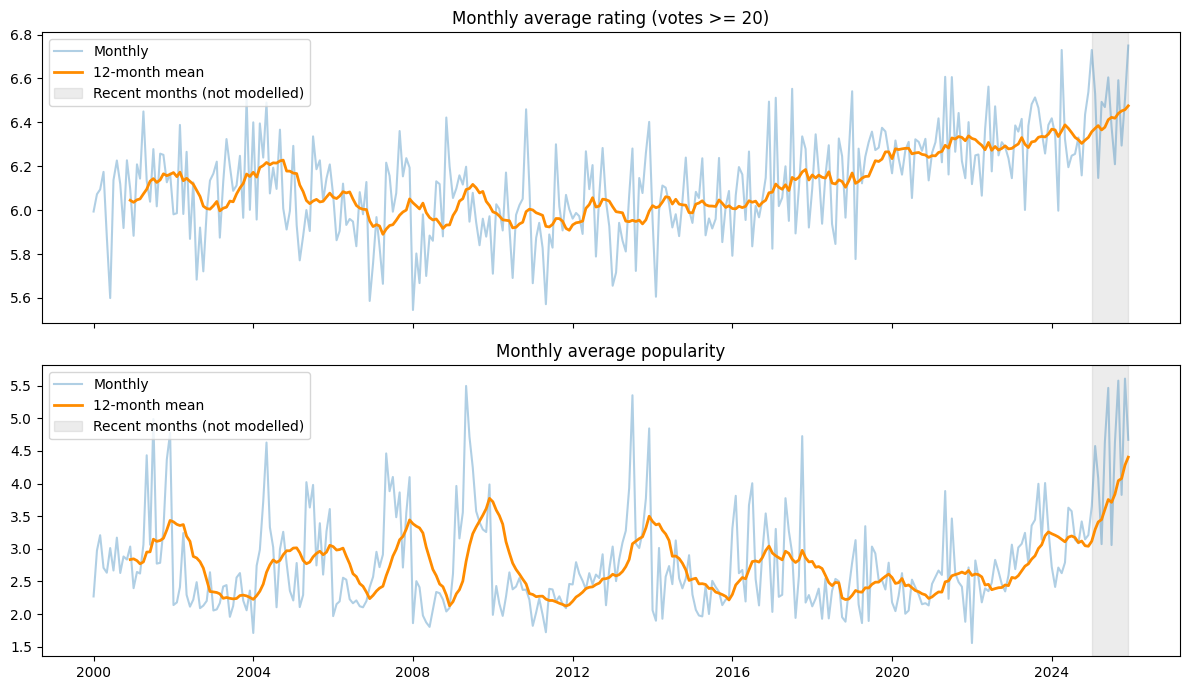

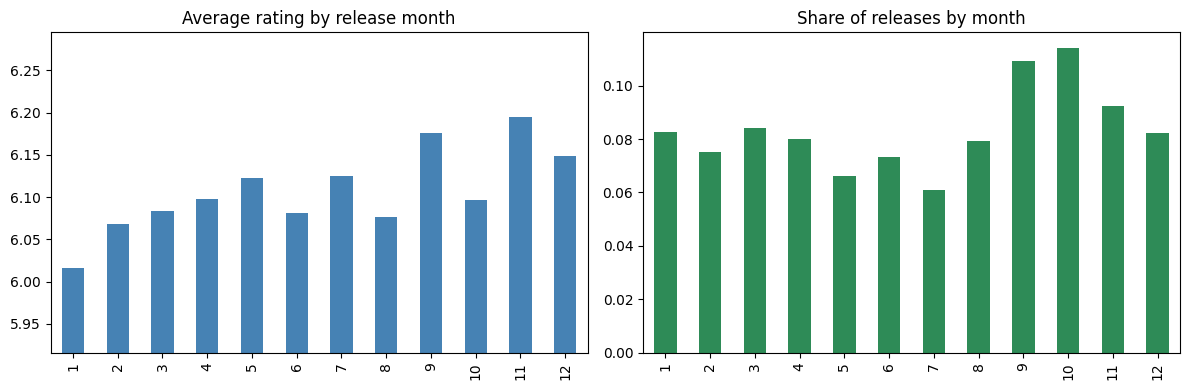

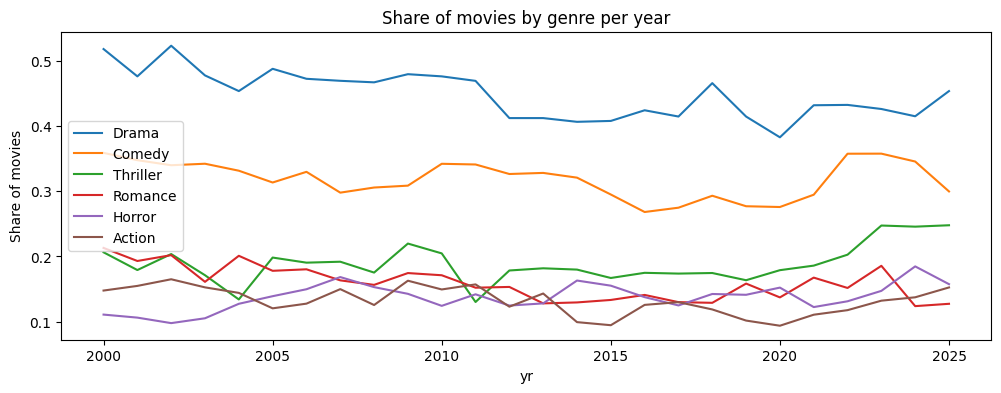

1     6.016
2     6.068
3     6.083
4     6.098
5     6.123
6     6.082
7     6.125
8     6.076
9     6.176
10    6.097
11    6.195
12    6.149


In [2]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for a, c, t in [(ax[0], "rating", "Monthly average rating (votes >= %d)" % MIN_V), (ax[1], "pop", "Monthly average popularity")]:
    a.plot(mon.index, mon[c], alpha=0.35, label="Monthly")
    a.plot(mon.index, mon[c].rolling(12).mean(), lw=2, color="darkorange", label="12-month mean")
    a.axvspan(mon.index[-DROP_LAST], mon.index[-1], color="grey", alpha=0.15, label="Recent months (not modelled)")
    a.set_title(t); a.legend(loc="upper left")
plt.tight_layout(); plt.show()

# seasonality: average by calendar month
cm = s.groupby(s.index.month).mean()
sh = mon["n_all"].groupby(mon.index.month).sum()
sh = sh / sh.sum()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
cm.plot(kind="bar", ax=ax[0], color="steelblue", title="Average rating by release month")
ax[0].set_ylim(cm.min() - 0.1, cm.max() + 0.1)
sh.plot(kind="bar", ax=ax[1], color="seagreen", title="Share of releases by month")
plt.tight_layout(); plt.show()

yr[top].plot(figsize=(12, 4), title="Share of movies by genre per year")
plt.ylabel("Share of movies"); plt.show()
print(cm.round(3).to_string())

## Step 3: Trend, seasonality and stationarity

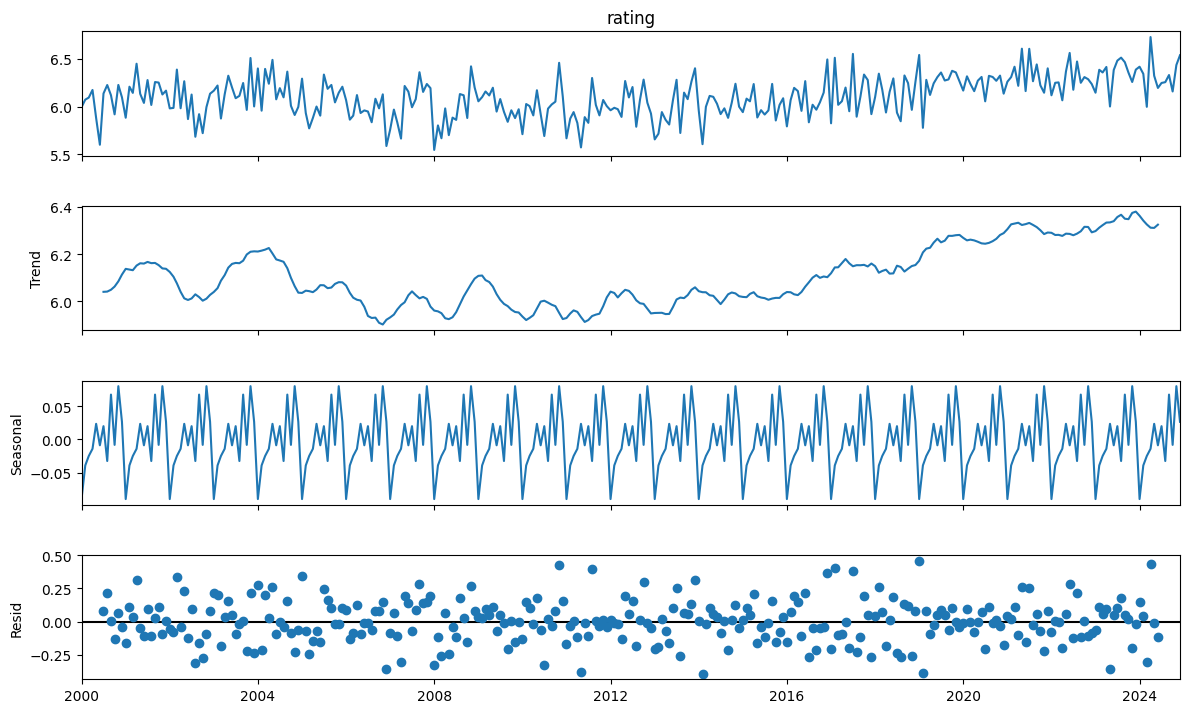

Seasonal strength: 0.07 | Trend strength: 0.41  (0 = none, 1 = very strong)
ADF p-value after 0 difference(s): 0.0008
Differencing used (d): 0


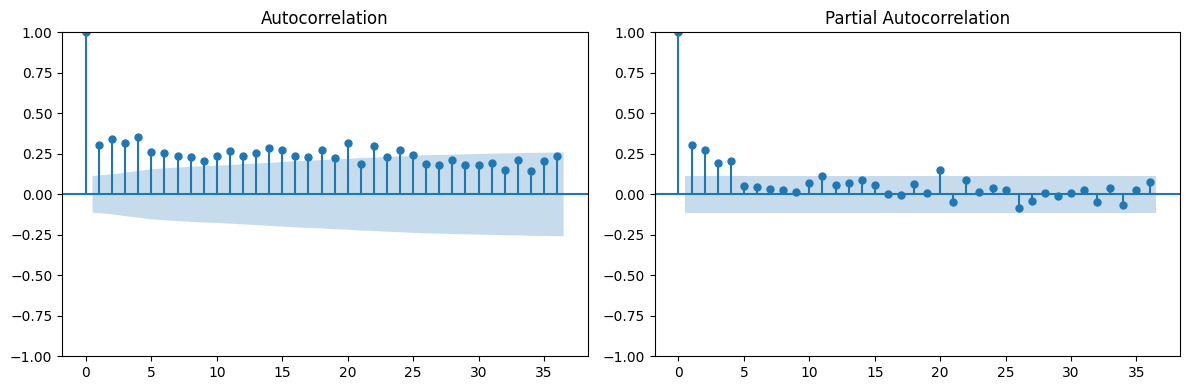

In [3]:
dec = seasonal_decompose(s, model="additive", period=12)
dec.plot(); plt.gcf().set_size_inches(12, 8); plt.show()

rs = dec.resid.dropna()
ss_ = max(0, 1 - rs.var() / (rs + dec.seasonal.loc[rs.index]).var())
st_ = max(0, 1 - rs.var() / (rs + dec.trend.loc[rs.index]).var())
print(f"Seasonal strength: {ss_:.2f} | Trend strength: {st_:.2f}  (0 = none, 1 = very strong)")

# ADF test: p < 0.05 means the series is stationary
d, x = 0, s.copy()
while True:
    p = adfuller(x.dropna())[1]
    print(f"ADF p-value after {d} difference(s): {p:.4f}")
    if p < 0.05 or d == 2: break
    x = x.diff().dropna(); d += 1
print("Differencing used (d):", d)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(x.dropna(), lags=36, ax=ax[0]); plot_pacf(x.dropna(), lags=36, ax=ax[1], method="ywm")
plt.tight_layout(); plt.show()

## Step 4: Forecasting models (train on all but the last %d months)

In [4]:
tr, te = s.iloc[:-TEST], s.iloc[-TEST:]
preds, fits = {}, {}

# 1. naive baseline: flat line at the last 12-month average
preds["Naive (last 12-mo mean)"] = pd.Series(tr.iloc[-12:].mean(), index=te.index)

# 2. SARIMA: small grid, best AIC on the training part
best = (np.inf, None, None)
for p in range(3):
    for q in range(3):
        for P in range(2):
            for Q in range(2):
                try:
                    f = SARIMAX(tr, order=(p, d, q), seasonal_order=(P, 0, Q, 12),
                                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
                    if f.aic < best[0]: best = (f.aic, ((p, d, q), (P, 0, Q, 12)), f)
                except Exception:
                    pass
so, ss = best[1]
print("SARIMA order chosen:", so, ss, "| AIC:", round(best[0], 1))
preds["SARIMA"] = pd.Series(best[2].forecast(len(te)).values, index=te.index); fits["SARIMA"] = best[2]

# 3. Holt-Winters (trend + yearly seasonality) and 4. Holt without seasonality
hw = ExponentialSmoothing(tr, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12).fit()
ho = ExponentialSmoothing(tr, trend="add", damped_trend=True).fit()
preds["Holt-Winters"] = pd.Series(hw.forecast(len(te)).values, index=te.index); fits["Holt-Winters"] = hw
preds["Holt (no season)"] = pd.Series(ho.forecast(len(te)).values, index=te.index); fits["Holt (no season)"] = ho
print("models fitted:", list(preds))

SARIMA order chosen: (1, 0, 1) (0, 0, 0, 12) | AIC: -133.4
models fitted: ['Naive (last 12-mo mean)', 'SARIMA', 'Holt-Winters', 'Holt (no season)']


## Step 5: Evaluate the models on the held-out months

                  model    MAE   RMSE  RMSE vs naive (%)
       Holt (no season) 0.1252 0.1621               -6.3
                 SARIMA 0.1308 0.1645               -4.9
           Holt-Winters 0.1326 0.1693               -2.1
Naive (last 12-mo mean) 0.1407 0.1729                0.0

Best model on the test months: Holt (no season)


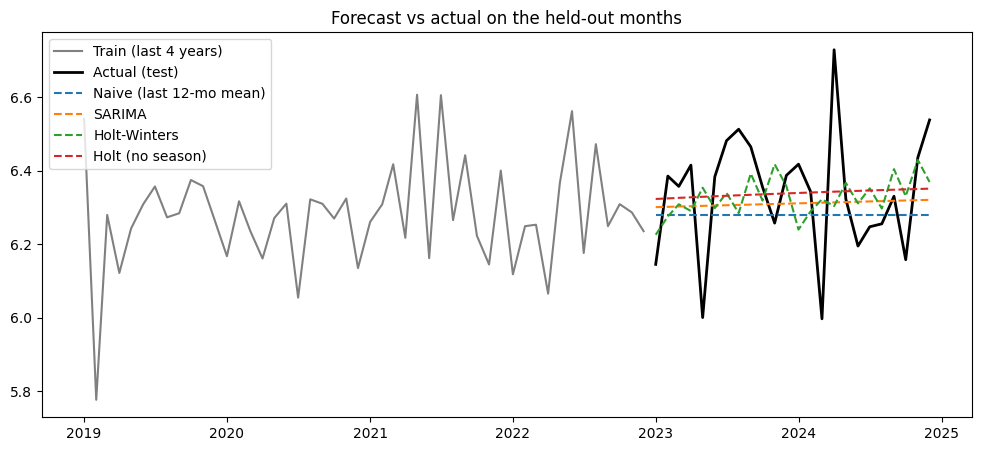

Ljung-Box p-value (lag 12): 0.181  (above 0.05 = no leftover pattern)


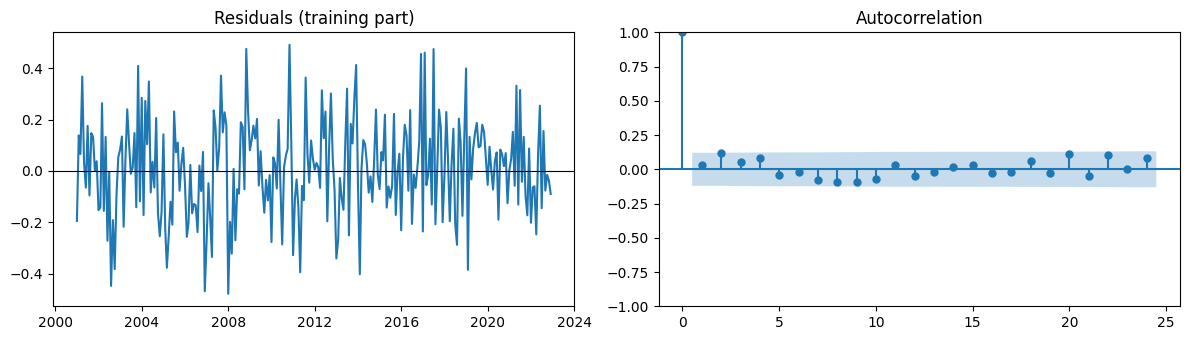

In [5]:
rows = [{"model": k, "MAE": mean_absolute_error(te, v), "RMSE": np.sqrt(mean_squared_error(te, v))} for k, v in preds.items()]
res = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
nv = res.loc[res["model"].str.startswith("Naive"), "RMSE"].iloc[0]
res["RMSE vs naive (%)"] = ((res["RMSE"] - nv) / nv * 100).round(1)
print(res.round(4).to_string(index=False))
best_name = res.loc[0, "model"]
print("\nBest model on the test months:", best_name)
if best_name.startswith("Naive"):
    print("No model beats the naive baseline. Report this honestly: the series has little predictable structure.")

plt.figure(figsize=(12, 5))
plt.plot(tr.iloc[-48:], color="grey", label="Train (last 4 years)")
plt.plot(te, "k", lw=2, label="Actual (test)")
for k, v in preds.items(): plt.plot(v, "--", label=k)
plt.title("Forecast vs actual on the held-out months"); plt.legend(); plt.show()

# residual check for the best model (should look like random noise)
if best_name in fits:
    e = pd.Series(fits[best_name].resid).iloc[12:]
    lb = acorr_ljungbox(e, lags=[12], return_df=True)
    print(f"Ljung-Box p-value (lag 12): {lb['lb_pvalue'].iloc[0]:.3f}  (above 0.05 = no leftover pattern)")
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    ax[0].plot(e); ax[0].axhline(0, color="k", lw=0.8); ax[0].set_title("Residuals (training part)")
    plot_acf(e, lags=24, ax=ax[1]); plt.tight_layout(); plt.show()

## Step 6: Final forecast, trend and genre findings

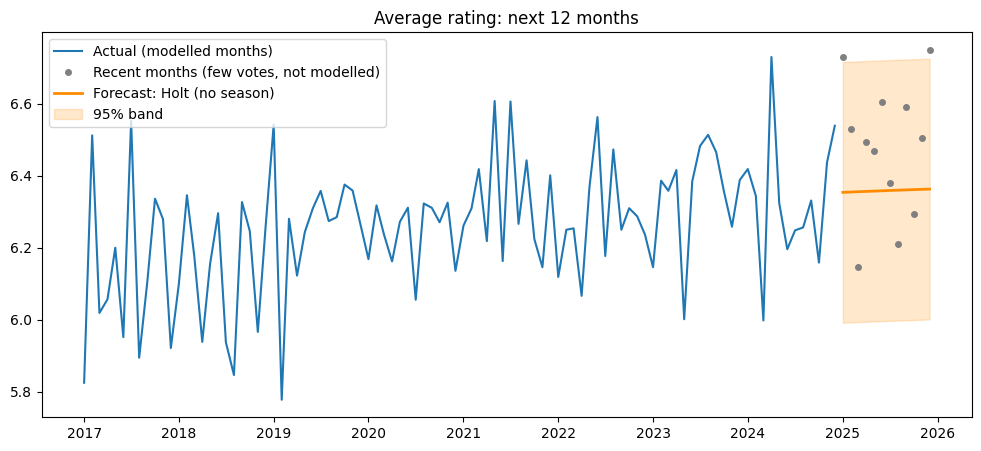

            forecast     lo     hi
2025-01-01     6.354  5.991  6.716
2025-02-01     6.354  5.992  6.717
2025-03-01     6.355  5.993  6.718
2025-04-01     6.356  5.994  6.719
2025-05-01     6.357  5.995  6.719
2025-06-01     6.358  5.996  6.720
2025-07-01     6.359  5.996  6.721
2025-08-01     6.360  5.997  6.722
2025-09-01     6.360  5.998  6.723
2025-10-01     6.361  5.999  6.724
2025-11-01     6.362  6.000  6.724
2025-12-01     6.363  6.000  6.725
Average rating 2000-2009: 6.058
Average rating 2010-2019: 6.057
Average rating 2020-2024: 6.307
Forecast average: 6.358 | last 12 months actual: 6.331

Genre share change, 2000-2004 vs 2020-2024:
genres
Horror      3.81
Thriller    3.33
Comedy     -1.78
Action     -3.46
Romance    -4.09
Drama      -7.22


In [6]:
def fc(name, x, h=H_FC):
    ix = pd.date_range(x.index[-1] + pd.offsets.MonthBegin(), periods=h, freq="MS")
    if name == "SARIMA":
        f = SARIMAX(x, order=so, seasonal_order=ss, enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        g = f.get_forecast(h); ci = g.conf_int()
        return pd.DataFrame({"forecast": g.predicted_mean.values, "lo": ci.iloc[:, 0].values, "hi": ci.iloc[:, 1].values}, index=ix)
    if name.startswith("Naive"):
        mu, sg = np.repeat(x.iloc[-12:].mean(), h), x.std()
    else:
        f = ExponentialSmoothing(x, trend="add", damped_trend=True, seasonal="add" if name == "Holt-Winters" else None,
                                 seasonal_periods=12 if name == "Holt-Winters" else None).fit()
        mu, sg = f.forecast(h).values, f.resid.std()
    return pd.DataFrame({"forecast": mu, "lo": mu - 1.96 * sg, "hi": mu + 1.96 * sg}, index=ix)   # approximate band

fo = fc(best_name, s)
plt.figure(figsize=(12, 5))
plt.plot(s.iloc[-96:], label="Actual (modelled months)")
plt.plot(mon["rating"][~mon["used"]], "o", color="grey", ms=4, label="Recent months (few votes, not modelled)")
plt.plot(fo["forecast"], color="darkorange", lw=2, label=f"Forecast: {best_name}")
plt.fill_between(fo.index, fo["lo"], fo["hi"], color="darkorange", alpha=0.2, label="95% band")
plt.title("Average rating: next %d months" % H_FC); plt.legend(loc="upper left"); plt.show()
print(fo.round(3).to_string())

# trend by period
for a, b in [(2000, 2009), (2010, 2019), (2020, s.index.max().year)]:
    print(f"Average rating {a}-{b}:", round(s[(s.index.year >= a) & (s.index.year <= b)].mean(), 3))
print("Forecast average:", round(fo["forecast"].mean(), 3), "| last 12 months actual:", round(s.iloc[-12:].mean(), 3))

# genre share change (first 5 years vs last 5 modelled years)
ly = s.index.max().year
ch = (gs.loc[ly - 4:ly].mean() - gs.loc[2000:2004].mean()) * 100
ch = ch.sort_values(ascending=False).round(2).rename("change in share (percentage points)")
print("\nGenre share change, 2000-2004 vs %d-%d:" % (ly - 4, ly)); print(ch.to_string())

## Step 7: Save results for the dashboard

In [7]:
mon.rename_axis("month").reset_index().to_csv("data/ts/monthly_series.csv", index=False)
yr.rename_axis("year").reset_index().to_csv("data/ts/yearly_summary.csv", index=False)
res.to_csv("data/ts/model_comparison.csv", index=False)
fo.assign(model=best_name).rename_axis("month").reset_index().to_csv("data/ts/forecast.csv", index=False)
ch.rename_axis("genre").reset_index().to_csv("data/ts/genre_share_change.csv", index=False)
cm.rename("avg_rating").rename_axis("month_of_year").reset_index().to_csv("data/ts/seasonality.csv", index=False)
print(sorted(os.listdir("data/ts")))

['forecast.csv', 'genre_share_change.csv', 'model_comparison.csv', 'monthly_series.csv', 'seasonality.csv', 'yearly_summary.csv']
